# Notebook 01 — Data Understanding

**IT4060 Fundamentals of Machine Learning — Group Assignment (group of 2)**

| | |
|---|---|
| Kusal Dissanayake | MS26929064 |
| Lahiru Sandeepa | MS26929378 |

**Task.** Predict whether a student will *drop out*, remain *enrolled* past the normal
course duration, or *graduate*, using information available at enrolment plus the first
two semesters of academic records.

**Dataset.** UCI Machine Learning Repository #697, *Predict Students' Dropout and
Academic Success*. 4,424 student records from the Polytechnic Institute of Portalegre,
Portugal, covering enrolments from 2008 to 2019 across agronomy, design, education,
nursing, journalism, management, social service and technology degrees.
36 features + 1 target, no missing values. The data is anonymised and GDPR compliant.

- DOI: [10.24432/C5MC89](https://doi.org/10.24432/C5MC89)
- Descriptor paper: Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022).
  Predicting Student Dropout and Academic Success. *Data, 7*(11), 146.
  [doi.org/10.3390/data7110146](https://doi.org/10.3390/data7110146)

**How the label was assigned.** The outcome is recorded at the end of the *normal*
duration of each course — three years for most degrees, four for Nursing. So `Enrolled`
does not mean "still studying happily": it means the student is still registered but has
not finished on schedule. This is why `Enrolled` is the hardest and smallest class.

**What this notebook does.** Loads the data, audits it, measures class balance,
separates genuinely numeric columns from integer-coded categories, looks for outliers
and redundant feature pairs, and finishes with an unsupervised K-Means check to see how
much of the outcome structure is visible without using the labels at all.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# same seed everywhere so results are reproducible
RANDOM_STATE = 42

# paths resolved from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "raw" / "data.csv"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("project root:", ROOT.name)

project root: ML-assignment-01


## 2. Load the data

The cached copy in `data/raw/` is semicolon-delimited, which is how the original
authors published it. If that file is missing (for example on a teammate's machine
before the first download) it is fetched from UCI with `ucimlrepo` and cached, so every
machine works from identical input.

In [2]:
def load_dropout_data(path=DATA_RAW):
    """Load the dataset, downloading it first if the cache is missing."""
    if path.exists():
        df = pd.read_csv(path, sep=";")
        # wrong separator if it all lands in one column
        if df.shape[1] == 1:
            df = pd.read_csv(path, sep=",")
        source = f"local cache ({path.name})"
    else:
        from ucimlrepo import fetch_ucirepo

        uci = fetch_ucirepo(id=697)
        df = pd.concat([uci.data.features, uci.data.targets], axis=1)
        path.parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(path, sep=";", index=False)
        source = "UCI repository (downloaded and cached)"
    return df, source


df, source = load_dropout_data()
print("loaded from:", source)
print("shape:", df.shape)

# stop here if the file did not load properly
assert df.shape == (4424, 37), f"expected (4424, 37), got {df.shape}"
df.head()

loaded from: local cache (data.csv)
shape: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Audit: types, duplicates, missing values

In [3]:
# types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [4]:
# check the no-missing-values claim
missing = df.isna().sum()
print("columns with missing values:", int((missing > 0).sum()))
print("total missing cells:", int(missing.sum()))
print("fully duplicated rows:", int(df.duplicated().sum()))
print("\ndtype counts:")
print(df.dtypes.value_counts())

columns with missing values: 0
total missing cells: 0
fully duplicated rows: 0

dtype counts:
int64      29
float64     7
str         1
Name: count, dtype: int64


In [5]:
# summary stats, transposed to read top to bottom
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


## 4. Class balance

The three outcomes are not equally represented. The size of the gap decides which
metrics are honest later: with `Graduate` at roughly half the data, a model that always
answers `Graduate` already scores near 50% accuracy while finding not one student at
risk. That is why the project reports macro precision, recall and F1 rather than
accuracy.

In [6]:
counts = df["Target"].value_counts()
balance = pd.DataFrame(
    {
        "count": counts,
        "percent": (counts / len(df) * 100).round(2),
    }
)
print(balance)
print(f"\nmajority-class baseline accuracy: {counts.max() / len(df):.4f}")
print(f"imbalance ratio (largest : smallest): {counts.max() / counts.min():.2f} : 1")

          count  percent
Target                  
Graduate   2209    49.93
Dropout    1421    32.12
Enrolled    794    17.95

majority-class baseline accuracy: 0.4993
imbalance ratio (largest : smallest): 2.78 : 1


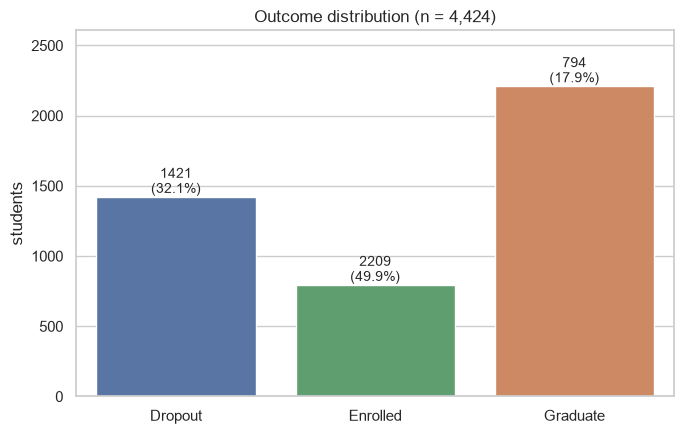

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
order = ["Dropout", "Enrolled", "Graduate"]
sns.countplot(data=df, x="Target", order=order, hue="Target", legend=False,
              palette="deep", ax=ax)

# percentages on top of the bars
for patch, label in zip(ax.patches, order):
    pct = counts[label] / len(df) * 100
    ax.annotate(f"{counts[label]}\n({pct:.1f}%)",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)

ax.set_title("Outcome distribution (n = 4,424)")
ax.set_xlabel("")
ax.set_ylabel("students")
ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
fig.savefig(FIGURES / "01_class_balance.png", dpi=150)
plt.show()

## 5. Which columns are really numeric?

Nine columns are stored as integers but carry no ordering at all — they are codes from
the Portuguese national registry. `Course` 9254 is not "more" than `Course` 171, and
`Application mode` 17 is not between 15 and 39 in any meaningful sense. Feeding these
straight into a model as numbers would invent an ordering that does not exist, so they
are one-hot encoded in notebook 02.

Two of the nine are arguably *ordinal* (the parents' qualification levels run roughly
from illiterate to doctorate), but the published codebook interleaves them with
"unknown" and course-specific codes, so the ordering is not clean enough to rely on.
All nine are therefore treated as nominal.

In [8]:
# registry codes, no natural order
NOMINAL_CODED = [
    "Marital Status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",          # spelled this way in the source file
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

# already 0/1
BINARY = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]

# continuous and count columns, these get scaled
CONTINUOUS = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

# all 36 must be grouped or notebook 02 drops a column
assigned = NOMINAL_CODED + BINARY + CONTINUOUS
assert len(assigned) == 36, f"{len(assigned)} columns assigned, expected 36"
assert set(assigned) | {"Target"} == set(df.columns), "group lists do not match the file"
print("all 36 features assigned to a group")

all 36 features assigned to a group


In [9]:
def column_group(name):
    if name in NOMINAL_CODED:
        return "nominal (coded)"
    if name in BINARY:
        return "binary"
    if name in CONTINUOUS:
        return "continuous / count"
    return "target"


cardinality = pd.DataFrame(
    {
        "group": [column_group(c) for c in df.columns],
        "dtype": df.dtypes.astype(str),
        "unique": df.nunique(),
        "most_common_share": [
            round(df[c].value_counts(normalize=True).iloc[0], 4) for c in df.columns
        ],
    }
)
cardinality.sort_values(["group", "unique"], ascending=[True, False])

,group,dtype,unique,most_common_share
Daytime/evening attendance,binary,int64,2,0.8908
Displaced,binary,int64,2,0.5484
Educational special needs,binary,int64,2,0.9885
Debtor,binary,int64,2,0.8863
Tuition fees up to date,binary,int64,2,0.8807
Gender,binary,int64,2,0.6483
Scholarship holder,binary,int64,2,0.7516
International,binary,int64,2,0.9751
Curricular units 1st sem (grade),continuous / count,float64,797,0.1623
Curricular units 2nd sem (grade),continuous / count,float64,782,0.1967


In [10]:
# cardinality decides how wide one-hot encoding gets
print("cardinality of the nine coded-nominal columns:")
print(df[NOMINAL_CODED].nunique().sort_values(ascending=False))
print("\ncolumns one-hot encoding would create if every level were kept:",
      int(df[NOMINAL_CODED].nunique().sum()))

cardinality of the nine coded-nominal columns:
Father's occupation       46
Father's qualification    34
Mother's occupation       32
Mother's qualification    29
Nacionality               21
Application mode          18
Course                    17
Previous qualification    17
Marital Status             6
dtype: int64

columns one-hot encoding would create if every level were kept: 220


In [11]:
# near-constant columns carry little information
dominance = pd.Series(
    {c: df[c].value_counts(normalize=True).iloc[0] for c in df.columns if c != "Target"}
).sort_values(ascending=False)
print("columns where one value covers more than 95% of rows:")
print(dominance[dominance > 0.95].round(4))

columns where one value covers more than 95% of rows:
Educational special needs    0.9885
Nacionality                  0.9751
International                0.9751
dtype: float64


## 6. Distributions of the continuous features

Nine columns are worth looking at individually: the three grade columns, age, the two
semester grade columns and the three macroeconomic indicators. The grade and credit
columns have a spike at zero — students who sat no evaluations — which is a real
category of student, not a recording error.

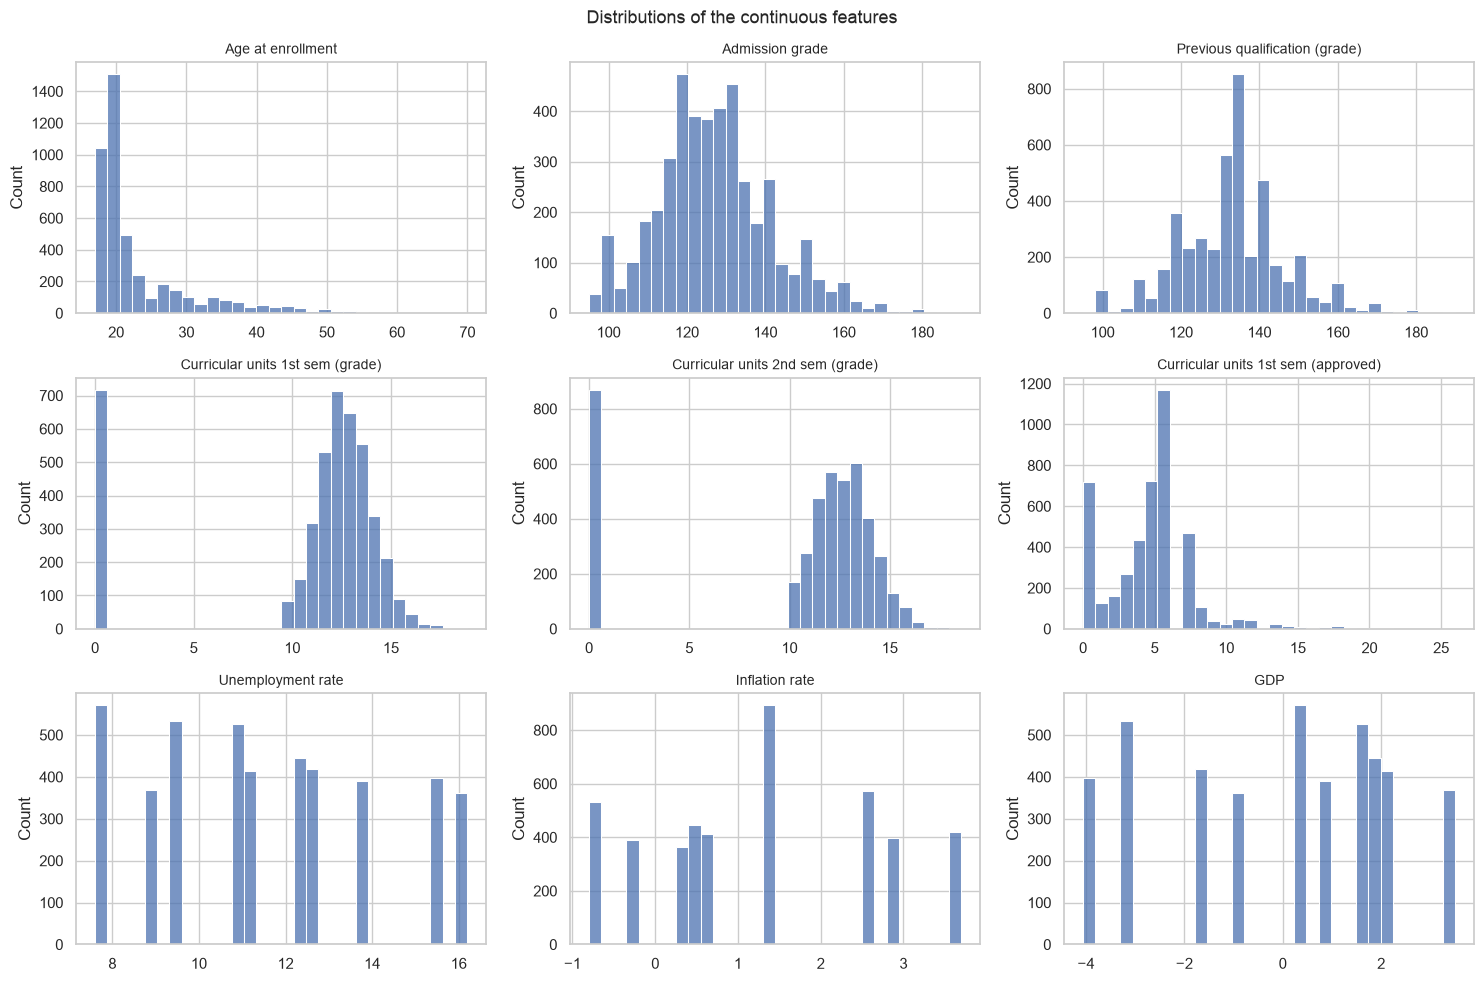

In [12]:
HIST_COLS = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (approved)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), HIST_COLS):
    sns.histplot(data=df, x=col, bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Distributions of the continuous features", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "01_distributions.png", dpi=150)
plt.show()

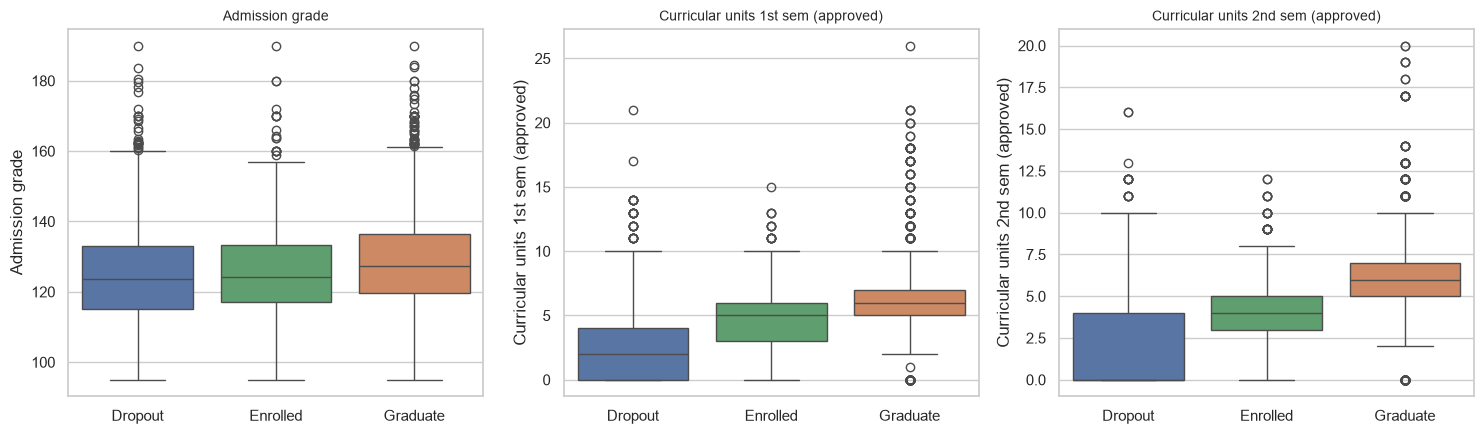

In [13]:
# grades split by outcome
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(
    axes,
    ["Admission grade",
     "Curricular units 1st sem (approved)",
     "Curricular units 2nd sem (approved)"],
):
    sns.boxplot(data=df, x="Target", y=col, order=order, hue="Target",
                legend=False, palette="deep", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURES / "01_grades_by_outcome.png", dpi=150)
plt.show()

## 7. Outliers — flagged, not deleted

The IQR rule flags anything more than 1.5 interquartile ranges outside the quartiles.
We flag and count, but **delete nothing**. A 60-year-old first-year student and a
student admitted with an unusually low grade are exactly the records an early-warning
system exists to catch; removing them would make the model look better while making it
useless. The same applies to the zero-grade rows.

In [14]:
def iqr_report(frame, columns):
    """Count values outside the 1.5*IQR fence."""
    rows = []
    for col in columns:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = ((frame[col] < low) | (frame[col] > high)).sum()
        rows.append(
            {
                "column": col,
                "Q1": round(q1, 2),
                "Q3": round(q3, 2),
                "IQR": round(iqr, 2),
                "lower fence": round(low, 2),
                "upper fence": round(high, 2),
                "flagged": int(flagged),
                "% flagged": round(flagged / len(frame) * 100, 2),
            }
        )
    return pd.DataFrame(rows).set_index("column")


iqr_report(
    df,
    ["Age at enrollment", "Admission grade", "Previous qualification (grade)",
     "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"],
)

,Q1,Q3,IQR,lower fence,upper fence,flagged,% flagged
column,,,,,,,
Age at enrollment,19.00,25.00,6.00,10.00,34.00,441,9.97
Admission grade,117.90,134.80,16.90,92.55,160.15,86,1.94
Previous qualification (grade),125.00,140.00,15.00,102.50,162.50,179,4.05
Curricular units 1st sem (grade),11.00,13.40,2.40,7.40,17.00,726,16.41
Curricular units 2nd sem (grade),10.75,13.33,2.58,6.88,17.21,877,19.82


## 8. Correlation and redundant feature pairs

The descriptor paper reports **13 feature pairs with Pearson correlation above 0.7**.
Reproducing those values is the load-correctness check for this notebook — if the file
had been parsed with the wrong separator or a shifted header, none of them would match.

Six of the seven published values we can check reproduce **exactly, to four decimal
places**. Two do not, and both of those involve integer-coded nominal columns. That is
not a loading error; it is the first concrete piece of evidence for why those nine
columns cannot be treated as numbers, and it is explained in section 8.2.

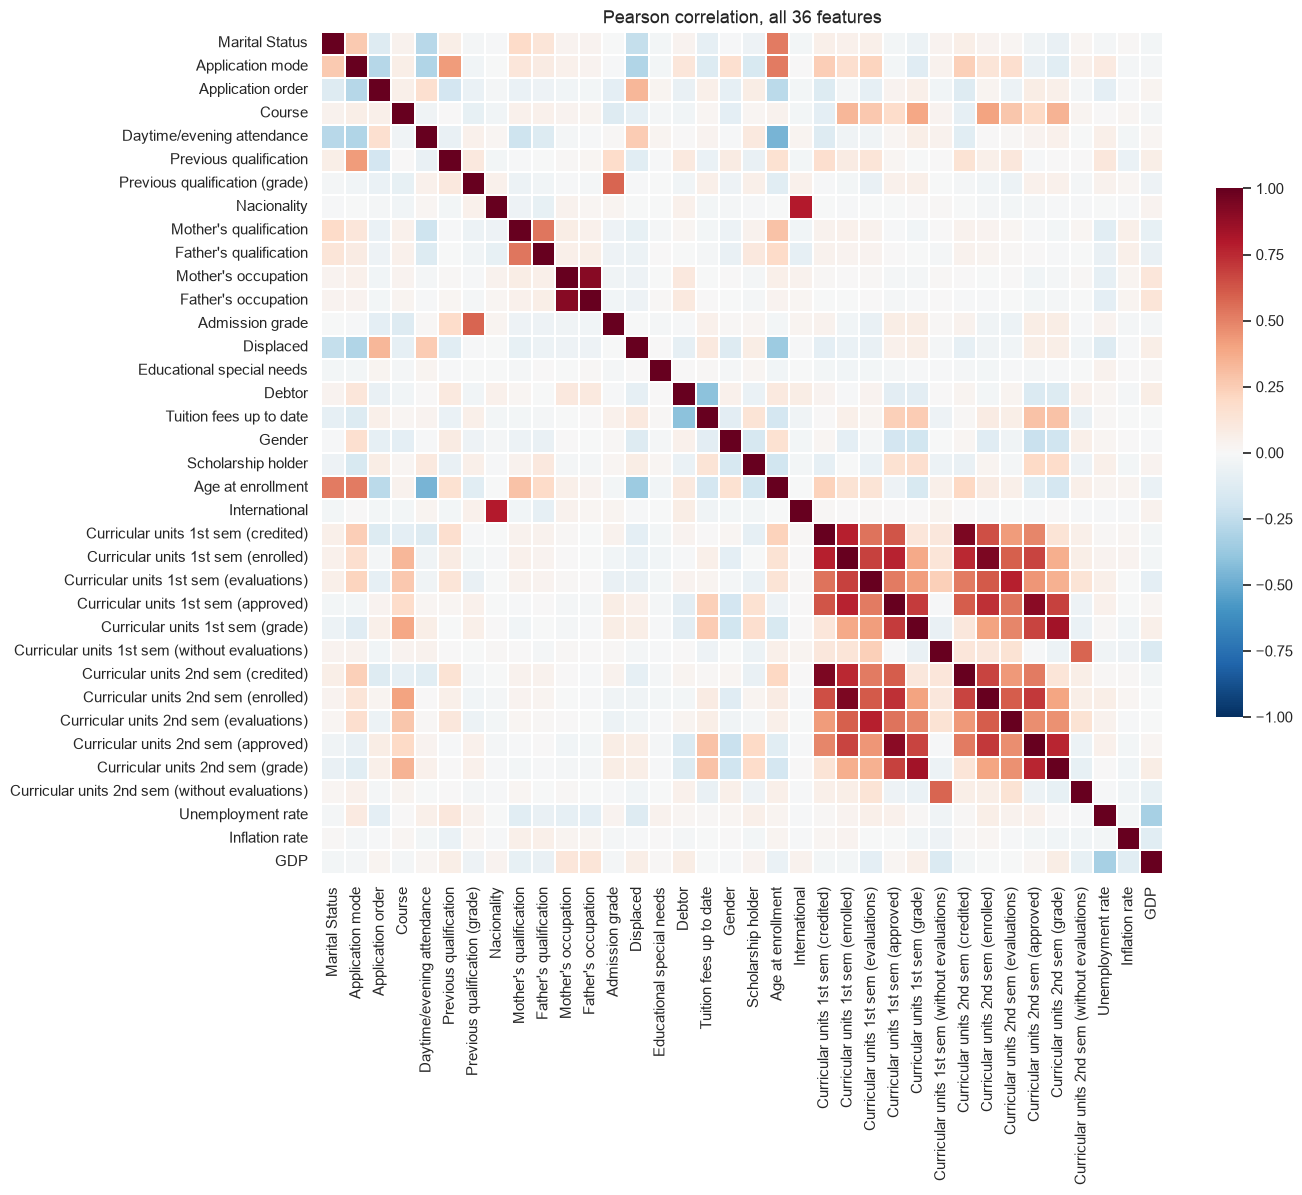

In [15]:
numeric = df.drop(columns=["Target"])
corr = numeric.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.2, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Pearson correlation, all 36 features", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "01_correlation_heatmap.png", dpi=150)
plt.show()

In [16]:
# upper triangle only, so each pair appears once
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = (
    corr.where(mask)
    .stack()
    .rename("pearson")
    .reset_index()
    .rename(columns={"level_0": "feature A", "level_1": "feature B"})
)
strong = (
    pairs[pairs["pearson"].abs() > 0.7]
    .assign(pearson=lambda d: d["pearson"].round(4))
    .sort_values("pearson", key=abs, ascending=False)
    .reset_index(drop=True)
)
print(f"pairs above |0.7|: {len(strong)}  (paper reports 13)")
strong

pairs above |0.7|: 13  (paper reports 13)


,feature A,feature B,pearson
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.9448
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.9426
2,Mother's occupation,Father's occupation,0.9105
3,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.9040
4,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.8372
5,Nacionality,International,0.7909
6,Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.7789
7,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.7743
8,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.7691
9,Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.7608


### 8.1 Load-correctness check

In [17]:
# checks that survive any recoding of the categorical columns
expected_counts = {"Graduate": 2209, "Dropout": 1421, "Enrolled": 794}
actual_counts = df["Target"].value_counts().to_dict()
assert actual_counts == expected_counts, f"class counts wrong: {actual_counts}"

# plain numeric pairs, so these must match the paper exactly
numeric_checks = {
    ("Curricular units 1st sem (credited)", "Curricular units 2nd sem (credited)"): 0.9448,
    ("Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"): 0.9426,
    ("Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)"): 0.9040,
    ("Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"): 0.8372,
    ("Curricular units 1st sem (evaluations)", "Curricular units 2nd sem (evaluations)"): 0.7789,
}
for (a, b), expected in numeric_checks.items():
    got = corr.loc[a, b]
    assert abs(got - expected) < 0.0001, f"{a} vs {b}: got {got:.4f}, expected {expected}"

print("load check passed")
print(f"  shape                  {df.shape}")
print(f"  class counts           {expected_counts}")
print(f"  {len(numeric_checks)} paper correlations    match to 4 decimal places")

load check passed
  shape                  (4424, 37)
  class counts           {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}
  5 paper correlations    match to 4 decimal places


### 8.2 The two pairs that do not match, and why that matters

| pair | paper | ours |
|---|---|---|
| `Nacionality` vs `International` | 0.9117 | 0.7909 |
| `Mother's occupation` vs `Father's occupation` | 0.7240 | 0.9105 |

Both pairs are made of **registry codes**, and Pearson correlation is not invariant to
how those codes are numbered. The occupation columns are published by UCI with the
detailed national codes — 0 to 10, then 90, 99, then 101 to 195 — while the paper's
table was computed on the coarse ten-group version. Re-labelling the same categories
with different integers changes the correlation while changing nothing about the data.

The practical consequence is that **Pearson is the wrong tool for these nine columns**.
A correlation of 0.79 between `Nacionality` and `International` understates the
relationship badly: as the next cell shows, `International` is a *deterministic
function* of `Nacionality`, so one of the two carries no information the other lacks.
Measured properly, with Cramér's V on the categories rather than Pearson on the codes,
the association is exactly 1.0.

In [18]:
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    """Association between two categorical columns, 0 to 1."""
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    return np.sqrt((chi2 / n) / min(r - 1, k - 1))


# International is just "not Portuguese"
derived = (df["Nacionality"] != 1).astype(int)
print("International reproduced from Nacionality:",
      bool((derived == df["International"]).all()))
print(f"  Pearson on the raw codes : {corr.loc['Nacionality', 'International']:.4f}")
print(f"  Cramer's V on categories : {cramers_v(df['Nacionality'], df['International']):.4f}")

print("\nassociation among the coded-nominal columns (Cramer's V > 0.3):")
nominal_assoc = []
for i, a in enumerate(NOMINAL_CODED):
    for b in NOMINAL_CODED[i + 1:]:
        v = cramers_v(df[a], df[b])
        if v > 0.3:
            nominal_assoc.append({"feature A": a, "feature B": b, "Cramer's V": round(v, 4)})
pd.DataFrame(nominal_assoc).sort_values("Cramer's V", ascending=False).reset_index(drop=True)

International reproduced from Nacionality: True
  Pearson on the raw codes : 0.7909
  Cramer's V on categories : 1.0000

association among the coded-nominal columns (Cramer's V > 0.3):


,feature A,feature B,Cramer's V
0,Mother's occupation,Father's occupation,0.5775
1,Mother's qualification,Father's qualification,0.4378
2,Application mode,Previous qualification,0.4160


### 8.3 Redundancy decisions

1. **Drop `International`.** It is a deterministic function of `Nacionality`, so keeping
   both adds a column and no information. We keep `Nacionality` because it is the richer
   of the two, and one-hot encoding with `min_frequency=0.01` will collapse its long
   tail — 110 of 4,424 students are non-Portuguese — into a single infrequent level,
   which recovers the `International` flag anyway.
2. **Keep both semesters.** The mirror pairs correlate at 0.78 to 0.94, which is high
   enough to hurt the interpretation of Logistic Regression coefficients but not high
   enough to justify discarding a whole semester of data. Instead, the collinearity is
   handled where it does damage: L2 regularisation in the Logistic Regression model, and
   the dedicated first-semester-only variant (Model B) in notebook 04, which answers the
   separate question of how early the warning can be issued.
3. **Keep both parents' occupations.** Their association is strong but far from
   deterministic, and they are substantively different variables.

## 9. Supervised or unsupervised?

Worth stating plainly before any model is fitted.

**This is a supervised problem.** Every one of the 4,424 rows carries a known outcome,
assigned at the end of the normal course duration. We want to learn a mapping from a
student's record to that outcome, and because the right answer is recorded we can
measure how wrong a prediction is and use that error to improve the model. Both
algorithms in this project — Logistic Regression and Random Forest — work this way.

**Unsupervised learning never sees the labels.** K-Means cannot be asked to find
dropouts, because the word "dropout" means nothing to it. All it can do is partition
students into groups that are compact in feature space, using whatever happens to
dominate the distances between them.

So why run it at all? As a diagnostic, for one question: *how much of the outcome
structure is visible in the raw feature geometry, before any supervision?* If the
clusters line up with the outcomes, the classes are separable on distance alone and
simple models should do well. If they cut across the outcomes, the signal is real but
tangled with other variation — course, age, parental background — and it takes a
supervised model to pull out the part that predicts dropout.

The cross-tabulation below compares clusters with the true outcomes. That is only
legitimate because the labels are **hidden during fitting** and used afterwards purely
to interpret what the algorithm found. Using them to choose `k` or to pick features
would make this a supervised method wearing an unsupervised label.

### 9.1 Choosing k — elbow and silhouette

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# scale first, K-Means works on distances
# nominal codes left out, distance between registry codes means nothing
X_cluster = StandardScaler().fit_transform(df[CONTINUOUS])
print("clustering matrix:", X_cluster.shape)

k_values = range(2, 9)
inertia, silhouette = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_cluster)   # true labels not used here
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_cluster, labels))

pd.DataFrame({"k": list(k_values), "inertia": np.round(inertia, 1),
              "silhouette": np.round(silhouette, 4)}).set_index("k")

clustering matrix: (4424, 19)


,inertia,silhouette
k,,
2,68611.8,0.4480
3,55263.8,0.3208
4,51633.0,0.1625
5,48166.0,0.1379
6,45357.4,0.1473
7,42963.5,0.1484
8,40989.6,0.1490


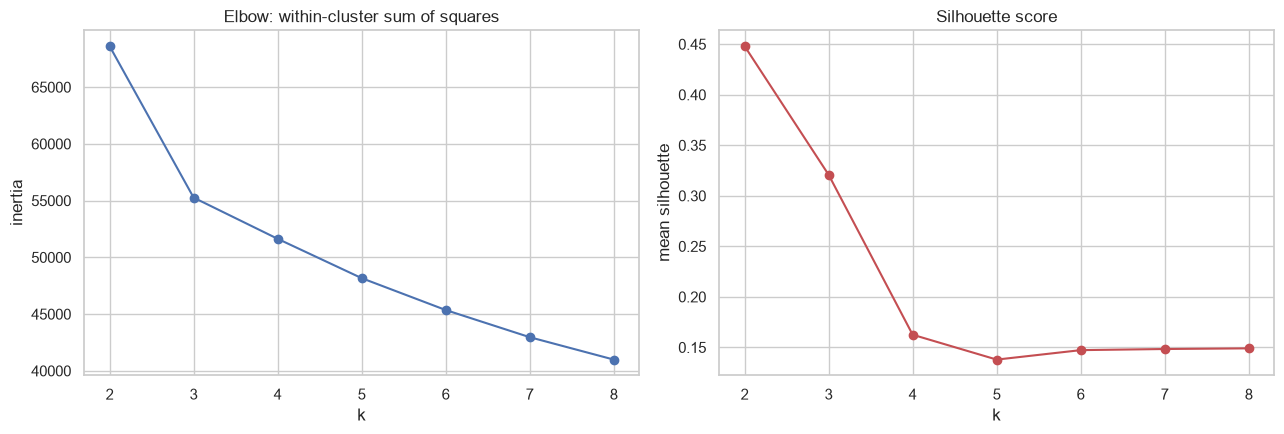

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), inertia, marker="o", color="#4C72B0")
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")

axes[1].plot(list(k_values), silhouette, marker="o", color="#C44E52")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("mean silhouette")

fig.tight_layout()
fig.savefig(FIGURES / "01_kmeans_selection.png", dpi=150)
plt.show()

### 9.2 Do the clusters match the outcomes?

We fit `k = 3` to match the three outcomes — not because the elbow says so, but because
that is the comparison worth making. If a three-way split of the feature space
reproduced the three outcomes, the labels would be almost redundant.

In [21]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
clusters = km3.fit_predict(X_cluster)

crosstab = pd.crosstab(clusters, df["Target"], rownames=["cluster"], colnames=["outcome"])
print("counts:")
print(crosstab)
print("\nrow percentages (what each cluster is made of):")
print((crosstab.div(crosstab.sum(axis=1), axis=0) * 100).round(1))
print("\ncluster sizes:", np.bincount(clusters))

counts:
outcome  Dropout  Enrolled  Graduate
cluster                             
0            677       684      1962
1             59        36       171
2            685        74        76

row percentages (what each cluster is made of):
outcome  Dropout  Enrolled  Graduate
cluster                             
0           20.4      20.6      59.0
1           22.2      13.5      64.3
2           82.0       8.9       9.1

cluster sizes: [3323  266  835]


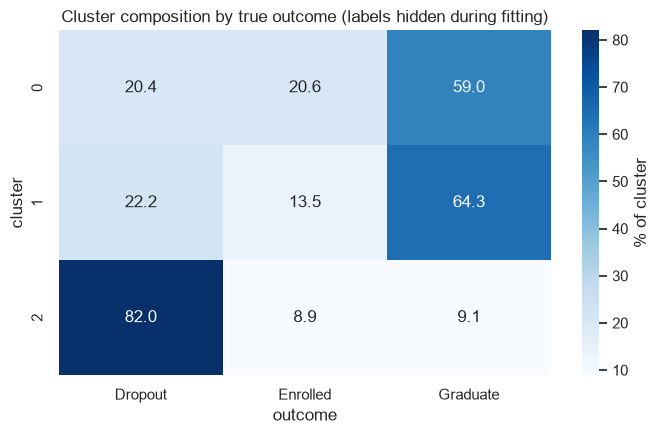

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap((crosstab.div(crosstab.sum(axis=1), axis=0) * 100).round(1),
            annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of cluster"}, ax=ax)
ax.set_title("Cluster composition by true outcome (labels hidden during fitting)")
fig.tight_layout()
fig.savefig(FIGURES / "01_cluster_crosstab.png", dpi=150)
plt.show()

### 9.3 What the clustering tells us

**The geometry prefers two groups, not three.** Inertia falls steeply from k = 2 to
k = 3 (68,612 to 55,264) and then flattens, and the silhouette score is highest at
k = 2 (0.448), drops to 0.321 at k = 3 and collapses to 0.16 from k = 4 onwards. Left to
itself, the data splits into two natural groups — not the three the outcome has.

**Forced to three, K-Means finds a dropout-dominant group.** Cluster 2 holds 835
students and is **82.0% Dropout**. It contains 685 of the 1,421 dropouts in the dataset.
The other two clusters lean towards `Graduate` (59.0% and 64.3%) and hold the rest.

That is a real result, but it has to be read carefully:

- As a dropout detector, cluster 2 would be **82% precise but only 48% complete** — it
  misses more than half of the students who actually drop out, and those are the ones
  sitting in a cluster that looks mostly like graduates. For an early-warning system,
  missing half the at-risk students is the expensive kind of error.
- **K-Means cannot tell us that cluster 2 is the dropout cluster.** We only know that
  after cross-tabulating against labels it never saw. Run on new students with no
  outcomes recorded, the algorithm would hand back three unlabelled groups and no way to
  say which one to worry about.
- **`Enrolled` is invisible to it.** No cluster is `Enrolled`-dominant; the class is
  smeared across all three at 20.6%, 13.5% and 8.9% — below its 17.9% base rate in two
  of them. The hardest class for the supervised models is the one unsupervised structure
  cannot see at all.

**Conclusion.** There is genuine geometric signal — students separate by academic load
and performance, and heavy dropout concentrates in one corner of that space. But the
separation is partial, it ignores the middle class entirely, and it comes with no labels
attached. Supervision is what converts "these students look unusual" into "this student
is likely to drop out", which is why the rest of this project is supervised.

## 10. Summary of preprocessing decisions

1. **No cleaning needed for missing values or duplicates** — there are none.
2. **Nine columns need one-hot encoding**, with `min_frequency=0.01` to control the
   width they would otherwise add.
3. **Eight columns are already binary** and pass through untouched.
4. **Nineteen continuous columns need scaling** for Logistic Regression; Random Forest
   does not care, but the shared pipeline applies it anyway for consistency.
5. **One column is dropped** — `International`, because it is a deterministic function
   of `Nacionality`. The semester mirror pairs are kept and their collinearity handled
   by regularisation instead.
6. **Outliers are flagged, not removed**, and that choice is defended in the report.
7. **The imbalance is 2.78 : 1** between `Graduate` and `Enrolled`, so macro-averaged
   metrics and `class_weight` / SMOTE experiments are required, not optional.

The train/test split is deliberately **not** made in this notebook. It is defined once
in notebook 02 and reused everywhere:

```python
train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
```

giving 3,539 development rows and 885 final-test rows. The final test set is not touched
until notebook 05.